In [1]:
#from exactextract import exact_extract 
import geopandas as gpd
import pandas as pd
import numpy as np
import xarray
import rioxarray
from pathlib import Path
from rasterio.features import rasterize
from scipy.ndimage import binary_erosion
import matplotlib.pyplot as plt
root = Path.cwd()

In [ ]:
# 2024 overall lighter (drought year?)
# 2023 somewhat lighter (june wildfire smoke?)

In [ ]:
## for paper, present as check of temporal robustness of growing season vs 3-season model. 
## point out that poor transferability of 2018 summer features suggests lack of robustness of 3-season model; 2021 happens to transfer to 2018 but can it transfer to other years?
## to do this we use pseudo-invariant features to assess stability of predictions year to year

#1. 
### get stable, dense canopy pixels
### >80% tree canopy within parks
## for these pixels only, get the median predicted value for 2021 - 2025, for 4-season and growing season model
## plot should show systematic underprediction by 4-season model in 2023 and 2024
## also: citywide totals for each year: models should agree in 2022 and 2025, but not 2023 and 2024.

# 2.
# figure out which features are responsible
# feature shift heatmap: get each pixel's difference (pred year - 2021). 
# rows are years, columns are features, cells are the median pixel deltas.
# highlights features that shifted the most for stable pixels (dense canopy or impervious) each year compared to 2021.

# 3.
## plot timeline of data acquisition each year
## check for gaps

## this will probably show that the growing season model is more stable
## could suggest assessing feature shift from training year data before deciding which model to use.


In [ ]:
# for citywide predictins, compare [spring,summer,fall] vs growing season 

## generate preds for all dates with 3-season model
# remake stability graphs

# remake aggregation graphs
## add 3-season vs gs comparison


## conduct cluster analysis on 3-season and growing season for 2021 (?)


In [2]:
def load_tif(f):
    return rioxarray.open_rasterio(f,masked=True).squeeze('band',drop=True)

def polygon_mask(gdf,template):
    gdf_t = gdf.to_crs(template.rio.crs) 

    # binary raster: pixels fully inside polygons = 1, else 0
    arr = rasterize(((geom,1) for geom in gdf_t.geometry if geom is not None),
                    out_shape=template.shape,
                    transform=template.rio.transform(),
                    fill=0,
                    all_touched=False,
                    dtype='uint8'
                    )
    return template.copy(data=arr.astype('bool'))
BLOCK_PX = 100                 # 1 km blocks at 10 m
N_BOOT, SEED = 1000, 0
def block_bootstrap_median(values_2d, mask, n_boot=N_BOOT, seed=SEED):
    """Median of the masked pixels with a 95% CI from resampling 1 km blocks.
    The same seed gives the same block resamples for every year and model (paired)."""
    rows, cols = np.nonzero(mask)
    v = values_2d[rows, cols]
    block = (rows // BLOCK_PX) * 100_000 + cols // BLOCK_PX
    codes, uniq = pd.factorize(block)
    per_block = [v[codes == k] for k in range(len(uniq))]
    rng = np.random.default_rng(seed)
    boots = np.array([np.median(np.concatenate([per_block[k] for k in rng.integers(len(uniq), size=len(uniq))]))
                      for _ in range(n_boot)])
    return np.median(v), *np.quantile(boots, [0.025, 0.975]), len(uniq)

In [2]:
stable_forest_vector = gpd.read_file(root / 'data' / 'nyc_selected_parks.gpkg')

In [6]:
stable_forest_vector.columns

Index(['feat_code', 'landuse', 'park_name', 'parknum', 'shape_area',
       'shape_leng', 'source_id', 'status', 'sub_code', 'system', 'geometry'],
      dtype='object')

In [3]:
## nyc parks boundaries
stable_forest_vector = gpd.read_file(root / 'data' / 'nyc_selected_parks.gpkg')
# manual patches from jfk, laguardia, midtown, hunts point
stable_imperv_vector = gpd.read_file(root / 'data' / 'stable_impervious.gpkg')

model1, label1 = 'three_seasons', 'three seasons'
model2, label2 = 'growing_season', 'growing season'
model3, label3 = 'summer_fall', 'two seasons'


years = ['nyc18','nyc19','nyc20','nyc21','nyc22','nyc23','nyc24','nyc25']
preds_model1 = {y: load_tif(root / 'model_outputs' / model1 / f'{y}_canopy_from_nyc21_{model1}_model.tif') for y in years}
preds_model2 = {y: load_tif( root / 'model_outputs' / model2 / f'{y}_canopy_from_nyc21_{model2}_model.tif') for y in years}
preds_model3 = {y: load_tif( root / 'model_outputs' / model3 / f'{y}_canopy_from_nyc21_{model3}_model.tif') for y in years}

lidar21 = load_tif(root / 'data' / 'nyc21' / 'nyc21_tree_canopy_lidar.tif')

# pixels valid in all rasters
valid = lidar21.notnull()
for p in list(preds_model1.values()) + list(preds_model2.values()):
    valid &= p.notnull()

## template grid to rasterize polygons
template = preds_model1['nyc21']



In [4]:
forest_pixels = polygon_mask(stable_forest_vector,template)
dense_forest = (forest_pixels & (lidar21 >= 95) & valid).values
dense_forest_eroded = binary_erosion(dense_forest,iterations=2) # remove outermost 2 pixels of each >95% patch
stable_forest = template.copy(data=dense_forest_eroded)  ## forest away from edges


imperv_pixels = polygon_mask(stable_imperv_vector,template)
stable_imperv_vals = ((lidar21 == 0) & valid & imperv_pixels).values
stable_imperv = template.copy(data=stable_imperv_vals)

print(f'num stable impervious pixels: {stable_imperv_vals.sum()}')
print(f'num dense forest way from edge pixels: {dense_forest_eroded.sum()}')
print(f'num park pixels: {dense_forest.sum()}')

num stable impervious pixels: 58083
num dense forest way from edge pixels: 42602
num park pixels: 119107


In [5]:
rows = []
for model, preds in ((label1, preds_model1),
                     (label2, preds_model2),
                     (label3,preds_model3)):
    for y, p in preds.items():
        for group, m in (('Stable dense canopy', stable_forest), ('Stable non-canopy', stable_imperv)):
            med, lo, hi, n_blocks = block_bootstrap_median(p.values, m.values)
            v = p.values[m.values]
            rows.append({'model': model, 'year': 2000 + int(y[-2:]), 'group': group, 'n_pixels': v.size, 'n_blocks':n_blocks,
                         'median': np.median(v), 'lo_ci': lo, 'hi_ci': hi,'mean': v.mean(), 'share_zero': (v == 0).mean()})
summary = pd.DataFrame(rows)


In [6]:
gs = summary.loc[(summary['model']== 'growing season')&(summary['group']=='Stable dense canopy')].copy()
ts = summary.loc[(summary['model']== 'three seasons')&(summary['group']=='Stable dense canopy')].copy()
two =  summary.loc[(summary['model']== 'two seasons')&(summary['group']=='Stable dense canopy')].copy()

In [7]:
two

,model,year,group,n_pixels,n_blocks,median,lo_ci,hi_ci,mean,share_zero
32,two seasons,2018,Stable dense canopy,42602,77,98.814194,98.355301,99.145367,97.504929,0.000000
34,two seasons,2019,Stable dense canopy,42602,77,96.656128,95.976394,97.372283,95.450226,0.000047
36,two seasons,2020,Stable dense canopy,42602,77,97.903595,97.322031,98.369309,96.846016,0.000000
38,two seasons,2021,Stable dense canopy,42602,77,99.620888,99.450349,99.725062,98.528084,0.000000
40,two seasons,2022,Stable dense canopy,42602,77,99.394020,99.116794,99.571402,98.093491,0.000000
42,two seasons,2023,Stable dense canopy,42602,77,97.948647,97.378144,98.383780,96.586014,0.000070
44,two seasons,2024,Stable dense canopy,42602,77,93.208481,92.406685,94.206608,91.223038,0.000070
46,two seasons,2025,Stable dense canopy,42602,77,98.131622,97.529758,98.554033,96.321938,0.000000


In [109]:

r_list = []
d_list = []
sim_years = [2018,2021,2022,2025]
diff_years = [2019,2020,2023,2024]

for y in sim_years:
    vals_y = []
    for d in [gs,ts,two]:
        vals_y.append(float(d.loc[d['year'] == y,'median'].values[0]))

    vals_y = np.array(vals_y)
    d1 = vals_y[0] - vals_y[1]
    d2 = vals_y[0] - vals_y[2]
    r = vals_y.max() - vals_y.min()
    d_list.append([d1,d2])
    r_list.append(r)

In [108]:
(2.5 + 2.9) / 2

2.7

In [110]:
r_list

[np.float64(0.9358062744140625),
 np.float64(0.10329437255859375),
 np.float64(0.28142547607421875),
 np.float64(1.1284027099609375)]

In [6]:
from matplotlib.ticker import MultipleLocator

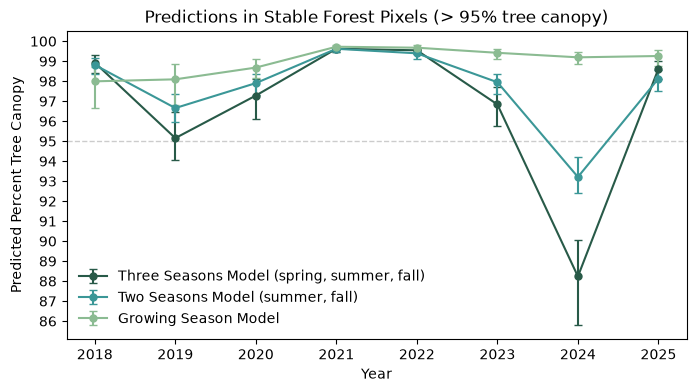

In [7]:


c1 = '#285A48'
c2 = '#8BBB92'
c3 = '#3B9797'

styles = {label1: {'label': f'{label1.title()} Model (spring, summer, fall)','offset':-0.06,'color':c1},label3: {'label':f'{label3.title()} Model (summer, fall)','offset':0.06,'color':c3}, label2: {'label':f'{label2.title()} Model','offset':0.06,'color':c2}}



fig, ax = plt.subplots(figsize=(8,4))

for (group, st) in styles.items():
    df = summary.loc[(summary['group']=='Stable dense canopy')&(summary['model']==group)].copy().sort_values('year')
    x = df['year'] 
    ax.errorbar(x,df['median'],yerr=[df['median']-df['lo_ci'],df['hi_ci']-df['median']],color=st['color'],label=st['label'],marker='o',ms=5,capsize=3)

ax.axhline(y=95,color='gray',alpha=0.4,ls='--',lw=1)
ax.set_xticks(x)
ax.set_xticklabels(x)
ax.set_ylabel('Predicted Percent Tree Canopy')
ax.set_xlabel('Year')
ax.yaxis.set_major_locator(MultipleLocator(1))

ax.legend(frameon=False)



ax.set_title('Predictions in Stable Forest Pixels (> 95% tree canopy)')
plt.show()


## add summer/fall model 

## add total citywide tree canopy figure

In [60]:
import re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import MultipleLocator

SEASONS = [('spring', 'Spring'), ('summer', 'Summer'), ('fall', 'Fall'), ('season', 'Growing season')]
YEAR_LABELS = {'nyc18': '2018','nyc19': '2019','nyc20':'2020','nyc22': '2022', 'nyc23': '2023', 'nyc24': '2024', 'nyc25': '2025'}

def order_columns(heat, feature_order=None):
    """Keep the median features and order them season by season, then by feature.
    Column names look like 'band_<feature>_<season>_median'. Returns (ordered DataFrame, column info)."""
    info = []
    for c in heat.columns:
        m = re.fullmatch(r'(?:band_)?(.+)_(spring|summer|fall|season)_median', str(c))
        if m:
            info.append({'col': c, 'feature': m.group(1), 'season': m.group(2)})
    info = pd.DataFrame(info)
    feats = feature_order or list(dict.fromkeys(info['feature']))          # default: order of first appearance
    info['s_rank'] = info['season'].map({s: i for i, (s, _) in enumerate(SEASONS)})
    info['f_rank'] = info['feature'].map({f: i for i, f in enumerate(feats)})
    info = info.sort_values(['s_rank', 'f_rank']).reset_index(drop=True)
    return heat[info['col']], info

def plot_shift_heatmap(heat, title=None, vmax=2,fname=None, feature_order=None, feature_labels=None, annotate=False):
    h, info = order_columns(heat, feature_order)
    h = h.rename(index=YEAR_LABELS)
    #vmax = 1.0 #np.nanmax(np.abs(h.values))
    fig, ax = plt.subplots(figsize=(0.22 * h.shape[1] + 2.5, 0.45 * h.shape[0] + 2.2))
    im = ax.imshow(h.values, cmap='RdBu_r', norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax), aspect='auto')

    # x labels: feature names; season names centred above each block; white lines between seasons
    labels = [feature_labels.get(f, f) if feature_labels else f for f in info['feature']]
    ax.set_xticks(range(h.shape[1])); ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_yticks(range(h.shape[0])); ax.set_yticklabels(h.index, fontsize=9)
    for s, name in SEASONS:
        idx = np.flatnonzero(info['season'].to_numpy() == s)
        if idx.size == 0:
            continue
        ax.text(idx.mean(), -0.75, name, ha='center', va='bottom', fontsize=9)
        if idx.min() > 0:
            ax.axvline(idx.min() - 0.5, color='white', lw=3)
    ax.set_ylim(h.shape[0] - 0.5, -0.5)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)

    if annotate:
        for i in range(h.shape[0]):
            for j in range(h.shape[1]):
                v = h.values[i, j]
                if np.isfinite(v) and abs(v) >= 0.5:                  # label only the large shifts
                    ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=6,
                            color='white' if abs(v) > 0.6 * vmax else 'black')

    cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
    cb.set_ticks(np.arange(-vmax, vmax + 0.001, 1)) 
    cb.update_ticks()
    cb.set_label('Median Change from 2021', fontsize=8)
    if title:
        ax.set_title(title, fontsize=10, pad=34, loc='left')
    plt.tight_layout()
    if fname:
        plt.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
import numpy as np, pandas as pd, xarray as xr
import joblib
from pathlib import Path
root = Path.cwd()

def feature_shift(f_base, f_year, stable, sample_step=20):
    """Median per-pixel change (year - base) at stable pixels, in units of the base year's citywide robust SD.
    f_base, f_year: feature DataArrays (band, y, x) on the same grid; stable: boolean (y, x)."""
    diff = (f_year - f_base).where(stable)
    med_change = diff.median(dim=('y', 'x'), skipna=True).compute()
    sub = f_base.isel(x=slice(None, None, sample_step), y=slice(None, None, sample_step))   # citywide sample
    q75, q25 = sub.quantile(0.75, dim=('y', 'x')).compute(), sub.quantile(0.25, dim=('y', 'x')).compute()
    robust_sd = (q75 - q25) / 1.349
    return (med_change / robust_sd).to_pandas()

f = {y: xr.open_zarr(f'data/{y}/{y}_seasonalstats.zarr')['features'] for y in ['nyc18','nyc19','nyc20','nyc21', 'nyc22', 'nyc23', 'nyc24', 'nyc25']}

# model_items = joblib.load(root / 'models' / 'nyc21' / f'nyc21_medians_only_models.joblib')
# features = model_items['input_features']
# 
for model in [model1,model2,model3]:
    shap = pd.read_csv(root / 'models' / 'nyc21' / 'shap' / f'nyc21_rgr_shap_{model}_mean.csv')
    features = shap.loc[:15,'feature']
    features = [x[5:] for x in features.values]

    ff = {y:f.sel(band=features) for y,f in f.items()}

    heat = pd.DataFrame({y: feature_shift(ff['nyc21'], ff[y], stable_forest) for y in ['nyc18','nyc19','nyc20','nyc22', 'nyc23', 'nyc24', 'nyc25']})

    heat.to_csv(root / 'model_outputs' / model / f'feature_shifts_{model}.csv')
# rows: years; columns: features -> plot with a diverging colormap centered on 0 (e.g. 'RdBu_r', vmin=-vmax)

In [78]:
model = 'summer_fall'
heat = pd.read_csv(root / 'model_outputs' / model / f'feature_shifts_{model}.csv')
heat = heat.set_index('band')
heat = heat[['nyc18','nyc19','nyc20','nyc22','nyc23','nyc24','nyc25']]
feat_names = {'tdv':'TDVI','ndr':'NDRE','psr':'PSRI','B11':'SWIR1 Band','nbr':'NBR','B03':'Green Band','s2w':'S2WI','B12':'SWIR2 Band','ndm':'NDMI','bsi':'BSI','B02':'Blue Band','B8A':'NIR Narrow','B08': 'NIR Band', 'B04': 'Red Band','B07': 'RE3 Band','B05':'RE1 Band','B06':'RE2 Band','grv':'GRVI'}

In [44]:
np.abs(heat.loc[heat['band']!='s2w_season_median',[x for x in heat.columns if x != 'band']]).mean().mean()

np.float64(0.10594194304799373)

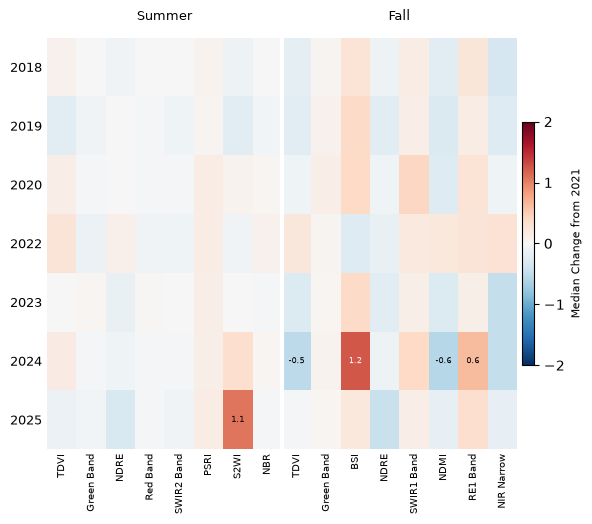

In [79]:
plot_shift_heatmap(heat.T,vmax=2,feature_labels=feat_names,annotate=True)

In [7]:
f['nyc21'].sel(band=features)

KeyError: "not all values found in index 'band'"